MODULO 3 CAP 5 VIDEO 1 GMM IN PYTHON

In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

In [6]:
data = load_wine()
X, y = data.data, data.target
target_names = data.target_names


In [9]:
scaler = StandardScaler()
X_std = scaler.fit_transform(X)


In [12]:
pca = PCA(n_components= 2, random_state = 42)
X_pca = pca.fit_transform(X_std)


In [15]:
#al posto di wcss di kmeans qui si usa log_likelihood

log_likelihood = []
n_components = range(1,10)

for k in n_components:
    gmm = GaussianMixture(n_components = k, covariance_type= "full", random_state=42)
    gmm.fit(X_std)
    log_likelihood.append(gmm.score(X_std))


c:\Users\Utente\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Utente\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Utente\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Utente\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: 

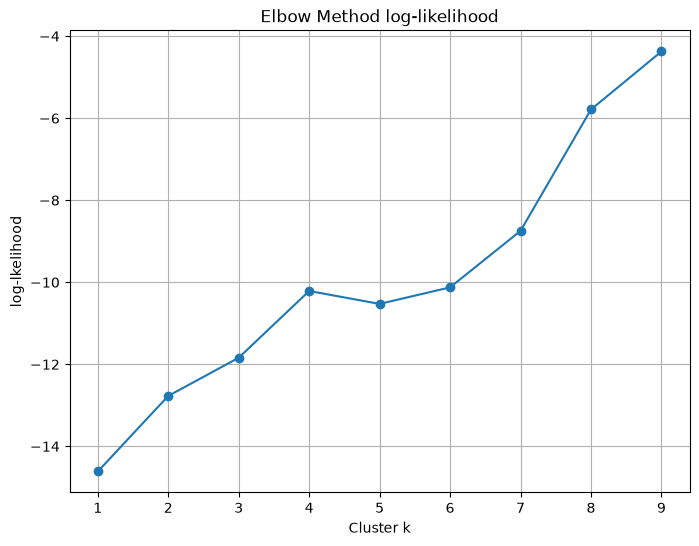

In [17]:
plt.figure(figsize=(8,6))
plt.plot(n_components, log_likelihood, marker= "o")
plt.title("Elbow Method log-likelihood")
plt.xlabel("Cluster k")
plt.ylabel("log-lkelihood")
plt.grid(True)
plt.show()

In [19]:
best_k = 3 
gmm= GaussianMixture(n_components = best_k, covariance_type="full", random_state = 42)
gmm.fit(X_std)
labels= gmm.predict(X_std)

print(labels.shape)
print(labels)




(178,)
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 2 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


c:\Users\Utente\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


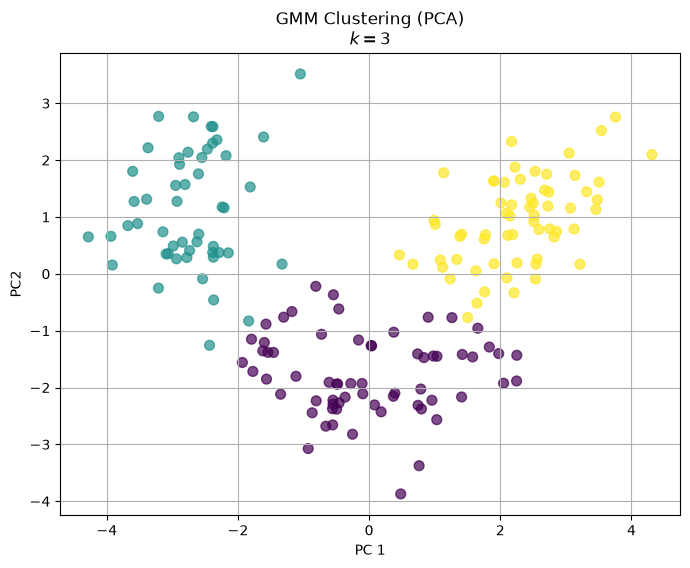

In [20]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0],X_pca[:,1], c = labels, cmap="viridis", s=50, alpha=0.7)
plt.title(f"GMM Clustering (PCA)\n$k = {best_k}$")
plt.xlabel("PC 1")
plt.ylabel("PC2")
plt.grid()
plt.show()

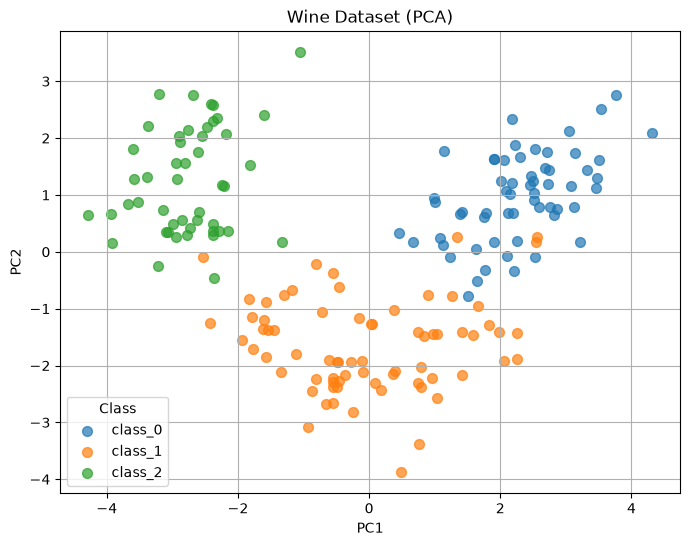

In [21]:
plt.figure(figsize=(8,6))
for label in np.unique(y):
    mask = (y==label)
    plt.scatter(X_pca[mask,0], X_pca[mask,1], s= 50, alpha =0.7, label=target_names[label] )
plt.title("Wine Dataset (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Class")
plt.grid()
plt.show()


In [22]:
#misurare l'accuracy
#la classe 0 reale non è necessariamente quella il nostro gmm ha creato perciò vanno adattate

def gmm_accuracy(y_true, y_pred):
    labels= np.zeros_like(y_pred)
    for cluster_id in np.unique(y_pred):
        mask=(cluster_id == y_pred)
        true_labels = y_true[mask]
        if true_labels.size >0:
            most_common = np.bincount(true_labels).argmax()
            labels[mask] = most_common

    return np.mean(labels== y_true)


In [23]:
accuracy = gmm_accuracy(y, labels)
print(f"GMM Clustering Accuracy. {accuracy * 100:.2f}%")

GMM Clustering Accuracy. 96.63%
